# Analiza błędów BERT 512 a obcięcie tekstu

Notebook sprawdza, czy błędy modelu BERT z obcięciem do 512 tokenów skupiają się na wiadomościach dłuższych niż limit. Jeśli tak,
podział na fragmenty (BELT) ma co poprawiać. Jeśli nie, obcięcie nie jest źródłem błędów.

- **Dane:** `predictions.csv` z notebooków `bert_512_spam_0` i `bert_512_spam_1`, czyli wynik modelu końcowego dla zbioru
  testowego ID i całego OOD, z progiem z walidacji i liczbą tokenów przed obcięciem.
- **Obcięta wiadomość:** dłuższa niż 512 tokenów razem z `[CLS]` i `[SEP]`.
- **Górna granica zysku z BELT:** wynik przy założeniu, że model poprawnie klasyfikuje każdą obciętą wiadomość, a nieobcięte
  zostają bez zmian. BELT nie może poprawić więcej niż ta granica.

In [ ]:
import sys
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import roc_auc_score

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "notebooks"))
from experiment_utils import ID_SOURCES, INK_SECONDARY, load_corpora

RESULTS = ROOT / "results" / "bert_512_error_analysis"
TABLES, FIGURES = RESULTS / "tables", RESULTS / "figures"
TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200, "display.max_columns", 50, "display.max_rows", 100, "display.float_format", "{:.3f}".format)

MAX_LENGTH = 512
VARIANTS = ("spam_0", "spam_1")
LENGTH_BINS = [0, 128, 256, 512, 1024, 2048, np.inf]
LENGTH_LABELS = ["≤128", "129-256", "257-512", "513-1024", "1025-2048", ">2048"]
ERROR_COLORS = {"fnr": "#2a78d6", "fpr": "#eb6834"}

predictions = pd.concat({
    variant: pd.read_csv(ROOT / "results" / f"bert_512_{variant}" / "tables" / "predictions.csv") for variant in VARIANTS
}, names=["wariant"]).reset_index(level=0).reset_index(drop=True)
predictions["błąd"] = predictions.pred != predictions.label
print(predictions.groupby(["wariant", "korpus"]).agg(n=("label", "size"), obcięte=("truncated", "mean"), błędy=("błąd", "sum")))

                    n  obcięte  błędy
wariant korpus                       
spam_0  ID      13070    0.202    269
        OOD      6124    0.000   3097
spam_1  ID      13070    0.202    174
        OOD      6124    0.000   3670


## Błędy według obcięcia

Dla wiadomości obciętych i nieobciętych w teście ID. `fnr` to udział phishingu (w `spam_1` także spamu) uznanego za
wiadomość pożądaną, `fpr` to udział wiadomości negatywnych uznanych za pozytywne. `udział_w_błędach_%` mówi, jaka część
wszystkich błędów danego rodzaju pochodzi z danej grupy.

In [2]:
def error_summary(frame):
    positives, negatives = frame[frame.label == 1], frame[frame.label == 0]
    return pd.Series({
        "n": len(frame),
        "pozytywne": len(positives),
        "fn": int((positives.pred == 0).sum()),
        "fp": int((negatives.pred == 1).sum()),
        "fnr": (positives.pred == 0).mean() if len(positives) else np.nan,
        "fpr": (negatives.pred == 1).mean() if len(negatives) else np.nan,
        "roc_auc": roc_auc_score(frame.label, frame.score) if frame.label.nunique() == 2 else np.nan,
    })


test = predictions[predictions.korpus == "ID"]
by_truncation = test.groupby(["wariant", "truncated"]).apply(error_summary, include_groups=False)
for column in ("fn", "fp"):
    by_truncation[f"udział_w_{column}_%"] = by_truncation[column] / by_truncation.groupby(level=0)[column].transform("sum") * 100
by_truncation.to_csv(TABLES / "bledy_wg_obciecia.csv")
display(by_truncation)

n  pozytywne     fn      fp   fnr   fpr  roc_auc  udział_w_fn_%  udział_w_fp_%
wariant truncated                                                                                       
spam_0  False     10436.000    990.000 55.000 122.000 0.056 0.013    0.993         64.706         66.304
        True       2634.000    263.000 30.000  62.000 0.114 0.026    0.981         35.294         33.696
spam_1  False     10436.000   4912.000 90.000  56.000 0.018 0.010    0.999         84.112         83.582
        True       2634.000   1320.000 17.000  11.000 0.013 0.008    0.998         15.888         16.418

Te same wielkości według źródła ID. Puste wartości oznaczają grupę z jedną klasą.

In [3]:
by_source = test.groupby(["wariant", "source", "truncated"]).apply(error_summary, include_groups=False)
by_source = by_source.reindex([index for variant in VARIANTS for name in ID_SOURCES for index in by_source.index
                               if index[:2] == (variant, name)])
by_source.to_csv(TABLES / "bledy_wg_zrodla_i_obciecia.csv")
display(by_source)

n  pozytywne     fn     fp   fnr   fpr  roc_auc
wariant source   truncated                                                       
spam_0  nazario  False      817.000    817.000 29.000  0.000 0.035   NaN      NaN
                 True       101.000    101.000  8.000  0.000 0.079   NaN      NaN
        nigerian False      173.000    173.000 26.000  0.000 0.150   NaN      NaN
                 True       162.000    162.000 22.000  0.000 0.136   NaN      NaN
        trec05   False     4477.000      0.000  0.000 82.000   NaN 0.018      NaN
                 True       909.000      0.000  0.000 41.000   NaN 0.045      NaN
        trec06   False     1360.000      0.000  0.000 16.000   NaN 0.012      NaN
                 True       222.000      0.000  0.000 11.000   NaN 0.050      NaN
        trec07   False     3609.000      0.000  0.000 24.000   NaN 0.007      NaN
                 True      1240.000      0.000  0.000 10.000   NaN 0.008      NaN
spam_1  nazario  False      817.000    817.000 13.000  0.000 0.016   NaN      NaN
                 True       101.000    101.000  2.000  0.000 0.020   NaN      NaN
        nigerian False      173.000    173.000  1.000  0.000 0.006   NaN      NaN
                 True       162.000    162.000  0.000  0.000 0.000   NaN      NaN
        trec05   False     4477.000   1781.000 43.000 31.000 0.024 0.011    0.998
                 True       909.000    407.000 13.000  1.000 0.032 0.002    0.999
        trec06   False     1360.000    316.000  1.000 12.000 0.003 0.011    1.000
                 True       222.000     45.000  2.000  3.000 0.044 0.017    0.988
        trec07   False     3609.000   1825.000 32.000 13.000 0.018 0.007    0.999
                 True      1240.000    605.000  0.000  7.000 0.000 0.011    0.998

## Błędy według długości wiadomości

Odsetek błędów w przedziałach długości. Przedziały powyżej 512 tokenów to wiadomości obcięte. Rosnący odsetek błędów w tych
przedziałach wskazywałby, że model traci informację z dalszej części tekstu.

n  pozytywne     fn     fp   fnr   fpr  roc_auc
wariant długość                                                         
spam_0  ≤128      5370.000    357.000 23.000 29.000 0.064 0.006    0.992
        129-256   3097.000    360.000 11.000 31.000 0.031 0.011    0.995
        257-512   1969.000    273.000 21.000 62.000 0.077 0.037    0.984
        513-1024  1273.000    202.000 26.000 47.000 0.129 0.044    0.974
        1025-2048 1064.000     59.000  3.000 15.000 0.051 0.015    0.983
        >2048      297.000      2.000  1.000  0.000 0.500 0.000    1.000
spam_1  ≤128      5370.000   2341.000 49.000 30.000 0.021 0.010    0.999
        129-256   3097.000   1778.000 25.000 10.000 0.014 0.008    0.999
        257-512   1969.000    793.000 16.000 16.000 0.020 0.014    0.998
        513-1024  1273.000    574.000 13.000  7.000 0.023 0.010    0.998
        1025-2048 1064.000    713.000  4.000  3.000 0.006 0.009    0.999
        >2048      297.000     33.000  0.000  1.000 0.000 0.004    0.997

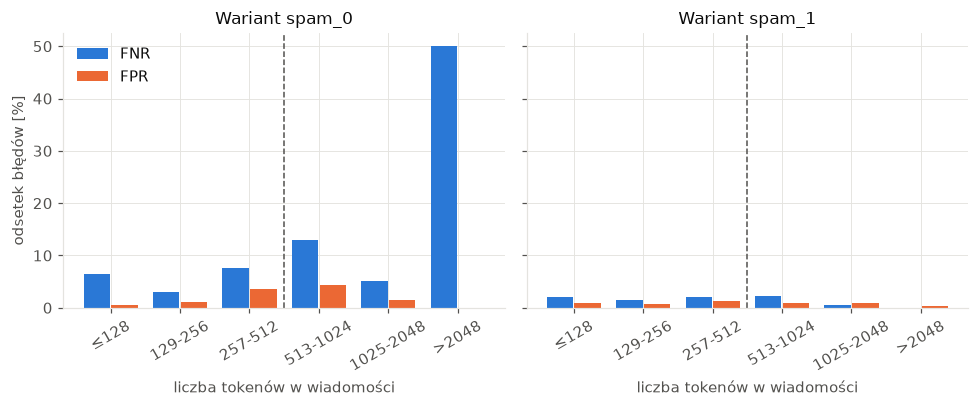

In [4]:
test = test.assign(długość=pd.cut(test.n_tokens, LENGTH_BINS, labels=LENGTH_LABELS))
by_length = test.groupby(["wariant", "długość"], observed=True).apply(error_summary, include_groups=False)
by_length.to_csv(TABLES / "bledy_wg_dlugosci.csv")
display(by_length)

figure, axes = plt.subplots(1, 2, figsize=(9, 3.8), sharey=True)
for axis, variant in zip(axes, VARIANTS):
    subset = by_length.loc[variant]
    positions = np.arange(len(subset))
    for offset, (column, color) in zip((-0.2, 0.2), ERROR_COLORS.items()):
        axis.bar(positions + offset, subset[column] * 100, width=0.38, color=color, label=column.upper())
    axis.axvline(positions[list(subset.index).index("513-1024")] - 0.5, color=INK_SECONDARY, linewidth=1, linestyle="--")
    axis.set_xticks(positions, subset.index, rotation=30)
    axis.set_xlabel("liczba tokenów w wiadomości")
    axis.set_title(f"Wariant {variant}")
axes[0].set_ylabel("odsetek błędów [%]")
axes[0].legend(loc="upper left")
figure.tight_layout()
figure.savefig(FIGURES / "bledy_wg_dlugosci.pdf")
plt.show()

## Górna granica zysku z BELT

Metryki ID przy obecnych predykcjach i przy założeniu, że każda obcięta wiadomość jest sklasyfikowana poprawnie. Różnica
to największa możliwa poprawa wynikająca z usunięcia obcięcia przy tym samym progu.

In [5]:
def threshold_metrics(labels, predicted):
    tp, fp = ((predicted == 1) & (labels == 1)).sum(), ((predicted == 1) & (labels == 0)).sum()
    fn = ((predicted == 0) & (labels == 1)).sum()
    return {"recall": tp / (tp + fn), "precision": tp / (tp + fp), "fpr": fp / (labels == 0).sum(),
            "f1": 2 * tp / (2 * tp + fp + fn), "błędy": int(fp + fn)}


bound_rows = []
for variant in VARIANTS:
    subset = test[test.wariant == variant]
    oracle = np.where(subset.truncated, subset.label, subset.pred)
    bound_rows += [{"wariant": variant, "predykcje": "BERT 512", **threshold_metrics(subset.label.to_numpy(), subset.pred.to_numpy())},
                   {"wariant": variant, "predykcje": "obcięte poprawnie", **threshold_metrics(subset.label.to_numpy(), oracle)}]
upper_bound = pd.DataFrame(bound_rows)
upper_bound.to_csv(TABLES / "gorna_granica_belt.csv", index=False)
display(upper_bound)

,wariant,predykcje,recall,precision,fpr,f1,błędy
0,spam_0,BERT 512,0.932,0.864,0.016,0.897,269
1,spam_0,obcięte poprawnie,0.956,0.908,0.010,0.931,177
2,spam_1,BERT 512,0.983,0.989,0.010,0.986,174
3,spam_1,obcięte poprawnie,0.986,0.991,0.008,0.988,146


## Przykłady błędów w obciętych wiadomościach

Najpewniejsze błędy wśród obciętych wiadomości testowych. `w_limicie` to początek tekstu widoczny dla modelu, a `po_limicie`
to fragment tuż za granicą obcięcia (w przybliżeniu, bo granica jest liczona w tokenach).

In [6]:
in_domain, _ = load_corpora()
texts = in_domain.set_index("raw_key").text
examples = test[test.truncated & test.błąd].assign(pewność=lambda frame: (frame.score - 0.5).abs())
examples = examples.sort_values("pewność", ascending=False).groupby(["wariant", "label"]).head(3)
for row in examples.itertuples():
    text = texts[row.id]
    cut = int(len(text) * MAX_LENGTH / row.n_tokens)
    print(f"{row.wariant} {row.source} {row.kind} etykieta={row.label} wynik={row.score:.3f} tokenów={row.n_tokens}")
    print("  w_limicie: ", text[:300].replace("\n", " "))
    print("  po_limicie:", text[cut:cut + 300].replace("\n", " "), "\n")

spam_1 trec06 spam etykieta=1 wynik=0.000 tokenów=613
  w_limicie:  CCGI Corporate Fact Sheet Novak Capital based upon information believed to be reliable herein prepared all material. The information contained herein is not guaranteed by Novak Capital to be accurate, and should not be considered to be all-inclusive. The companies that are discussed in this opinion 
  po_limicie: rs, and other risks identified in a companies` annual report on Form 10-K or 10-KSB and other filings made by such company with the Securities and Exchange Commission. You should consider these factors in evaluating the forward-looking statements included herein, and not place undue reliance on such 

spam_1 nazario phishing etykieta=1 wynik=0.000 tokenów=1430
  w_limicie:  libvirt update Ubuntu Security Notice USN-1008-3 October 23, [YEAR] libvirt update [URL] A security issue affects the following Ubuntu releases: Ubuntu 10.04 LTS This advisory also applies to the corresponding versions of Kubuntu, Edubuntu,